In [3]:
import numpy as np
import pandas as pd

In [4]:
#load dataset
df=pd.read_csv("KaggleDataset.csv")

In [4]:
#view the dataset
df.head()

,Dataset Name,Created By,Last Updated in number of days,Usability Score,Number of File,Type of file,Size,Total Votes,Category
0,Animal Crossing New Horizons Catalog,Jessica Li,1095,8.8,30,CSV,591 kB,42360,Gold
1,Credit Card Fraud Detection,Machine Learning Group - Ulb,2190,8.5,1,CSV,69 MB,11038,Gold
2,Covid-19 Open Research Dataset Challenge,Allen Institute For Ai,730,8.8,717120,"JSON, CSV, other",20 GB,10729,Gold
3,Netflix Movies And Tv Shows,Shivam Bansal,730,10,1,CSV,1 MB,8161,Gold
4,Chest X-Ray Images (Pneumonia),Paul Mooney,2190,7.5,5856,other,2 GB,6168,Gold


In [5]:
df.tail()


,Dataset Name,Created By,Last Updated in number of days,Usability Score,Number of File,Type of file,Size,Total Votes,Category
2472,Adidas Vs Nike,Kash,1095,10,1,CSV,284 kB,80,Bronze
2473,World Happiness Report 2023,Ajaypal Singh,365,9.4,1,CSV,7 kB,80,Bronze
2474,Tiktok Trending Videos,Erik Van De Ven,1095,8.2,1005,"other, JSON, CSV",3 GB,80,Bronze
2475,Spam Email Classification,Ashfak Yeafi,60,10,1,CSV,212 kB,80,Silver
2476,House Prices Dataset,Lisette,2190,5.9,4,"CSV, other",204 kB,80,Bronze


In [6]:
df.shape

(2477, 9)

In [7]:
df.columns

Index(['Dataset Name', 'Created By', 'Last Updated in number of days',
       'Usability Score', 'Number of File', 'Type of file', 'Size',
       'Total Votes', 'Category'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2477 entries, 0 to 2476
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Dataset Name                    2477 non-null   str  
 1   Created By                      2477 non-null   str  
 2   Last Updated in number of days  2477 non-null   str  
 3   Usability Score                 2477 non-null   str  
 4   Number of File                  2477 non-null   str  
 5   Type of file                    2477 non-null   str  
 6   Size                            2477 non-null   str  
 7   Total Votes                     2477 non-null   str  
 8   Category                        2477 non-null   str  
dtypes: str(9)
memory usage: 174.3 KB


In [9]:
#find the missing values
df.isnull().sum()

Dataset Name                      0
Created By                        0
Last Updated in number of days    0
Usability Score                   0
Number of File                    0
Type of file                      0
Size                              0
Total Votes                       0
Category                          0
dtype: int64

In [10]:
print(df.isnull().sum().sum())

0


In [11]:
#Handle missing values using pandas and numpy
#df['Last Updated in number of days']
#pd.to_numeric(df['Last Updated in number of days'],errors='coerce')
df['Last Updated in number of days']= df['Last Updated in number of days'].fillna(0)



In [12]:
df['Last Updated in number of days'].isnull().sum()

np.int64(0)

In [13]:
df.dtypes

Dataset Name                      str
Created By                        str
Last Updated in number of days    str
Usability Score                   str
Number of File                    str
Type of file                      str
Size                              str
Total Votes                       str
Category                          str
dtype: object

In [14]:
#handle string data 
numric_series=pd.to_numeric(df['Number of File'],errors='coerce')
median_value=numric_series.median()
df['Number of File']=df['Number of File'].fillna(median_value)

In [15]:
df['Number of File'].isnull().sum()

np.int64(0)

In [16]:
df['Type of file']=df['Type of file'].fillna('Unknown')

In [17]:
df.isnull().sum()

Dataset Name                      0
Created By                        0
Last Updated in number of days    0
Usability Score                   0
Number of File                    0
Type of file                      0
Size                              0
Total Votes                       0
Category                          0
dtype: int64

In [18]:
df['Category']=df['Category'].fillna('Unknown')

In [19]:
print(df['Number of File'].describe())

count     2477
unique     461
top          1
freq      1055
Name: Number of File, dtype: object


In [20]:
df.describe()

,Dataset Name,Created By,Last Updated in number of days,Usability Score,Number of File,Type of file,Size,Total Votes,Category
count,2477,2477,2477,2477,2477,2477,2477,2477,2477
unique,2438,1507,61,43,461,37,819,628,10
top,Titanic,Larxel,1460,10,1,CSV,2 MB,84,Silver
freq,4,33,351,867,1055,1538,83,43,1007


In [21]:
numric_series=pd.to_numeric(df['Size'],errors='coerce')
median_value=numric_series.median()
df['Size']=df['Size'].fillna(median_value)

In [22]:
df.describe()


,Dataset Name,Created By,Last Updated in number of days,Usability Score,Number of File,Type of file,Size,Total Votes,Category
count,2477,2477,2477,2477,2477,2477,2477,2477,2477
unique,2438,1507,61,43,461,37,819,628,10
top,Titanic,Larxel,1460,10,1,CSV,2 MB,84,Silver
freq,4,33,351,867,1055,1538,83,43,1007


In [23]:
#Remove duplicate rows
print(df.duplicated().sum())

0


In [24]:
df[df.duplicated(keep=False)]

,Dataset Name,Created By,Last Updated in number of days,Usability Score,Number of File,Type of file,Size,Total Votes,Category


In [25]:
#then remove duplicate rows
df=df.drop_duplicates()

In [26]:
print(df.duplicated().sum())

0


In [27]:
#clean text values
df["Category"]=df["Category"].str.strip().str.title()

In [28]:
df["Dataset Name"]=df["Dataset Name"].str.strip().str.title()

In [29]:
df["Created By"]=df["Created By"].str.strip().str.title()

In [30]:
#check unsual values and oulier 
df["Category"].describe()

count       2477
unique        10
top       Silver
freq        1007
Name: Category, dtype: object

In [31]:
df["Created By"].describe()

count       2477
unique      1507
top       Larxel
freq          33
Name: Created By, dtype: object

In [32]:
print("Dataset shape:",df.shape)
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows")
print(df.duplicated().sum)
print("Data types")
print(df.dtypes)
print("First five rows")
print(df.head())

Dataset shape: (2477, 9)
Missing values:
Dataset Name                      0
Created By                        0
Last Updated in number of days    0
Usability Score                   0
Number of File                    0
Type of file                      0
Size                              0
Total Votes                       0
Category                          0
dtype: int64
Duplicate rows
<bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
2472    False
2473    False
2474    False
2475    False
2476    False
Length: 2477, dtype: bool>
Data types
Dataset Name                      str
Created By                        str
Last Updated in number of days    str
Usability Score                   str
Number of File                    str
Type of file                      str
Size                              str
Total Votes                       str
Category                          str
dtype: object
First five rows
               

In [33]:
df.head()

,Dataset Name,Created By,Last Updated in number of days,Usability Score,Number of File,Type of file,Size,Total Votes,Category
0,Animal Crossing New Horizons Catalog,Jessica Li,1095,8.8,30,CSV,591 kB,42360,Gold
1,Credit Card Fraud Detection,Machine Learning Group - Ulb,2190,8.5,1,CSV,69 MB,11038,Gold
2,Covid-19 Open Research Dataset Challenge,Allen Institute For Ai,730,8.8,717120,"JSON, CSV, other",20 GB,10729,Gold
3,Netflix Movies And Tv Shows,Shivam Bansal,730,10,1,CSV,1 MB,8161,Gold
4,Chest X-Ray Images (Pneumonia),Paul Mooney,2190,7.5,5856,other,2 GB,6168,Gold


In [34]:
df.to_csv("KaggleDataset.csv",index=False)

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt


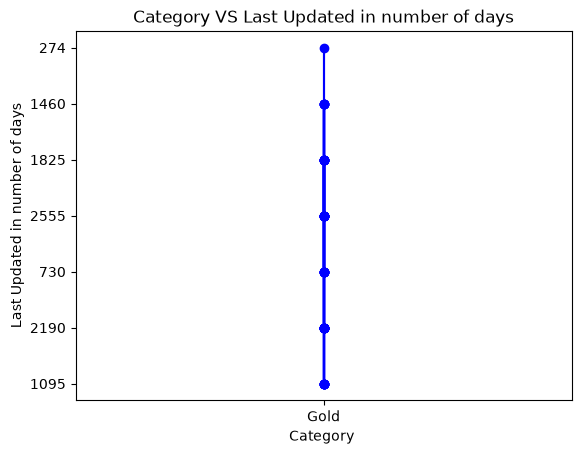

In [36]:
#line plot
df_sample=df.head(50)
plt.plot(df_sample['Category'],df_sample['Last Updated in number of days'],marker='o',color='blue')
plt.title('Category VS Last Updated in number of days')
plt.xlabel('Category ')
plt.ylabel('Last Updated in number of days')
plt.show()

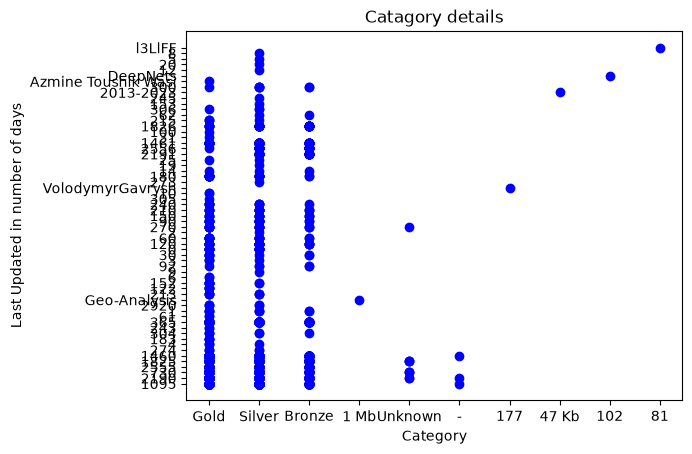

In [37]:
#Scatter plot
plt.scatter(df['Category'],df['Last Updated in number of days'],color='blue')
plt.title('Catagory details')
plt.xlabel('Category')
plt.ylabel('Last Updated in number of days')
plt.show()

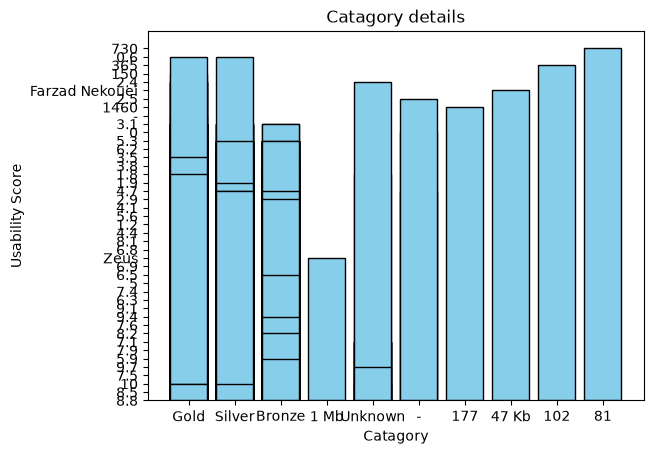

In [38]:
#bar graph
plt.bar(df['Category'],df['Usability Score'],color='skyblue',edgecolor='black')
plt.title('Catagory details')
plt.xlabel('Catagory')
plt.ylabel('Usability Score')
plt.show()

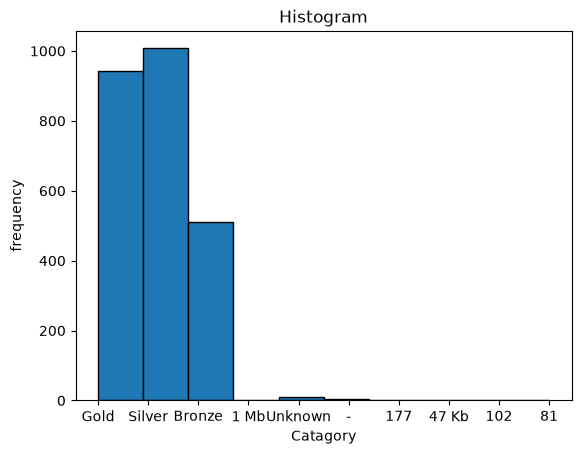

In [39]:
#Histogram
x=df["Category"]
plt.hist(x, bins=10, edgecolor='black')
plt.title("Histogram")
plt.xlabel("Catagory")
plt.ylabel("frequency")
plt.show()

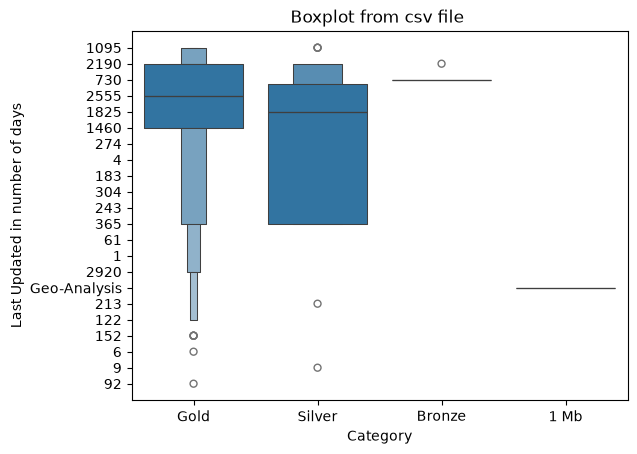

In [40]:
#boxplot
sns.boxenplot(data=df.head(500),x="Category",y="Last Updated in number of days")
plt.title("Boxplot from csv file ")
plt.show()

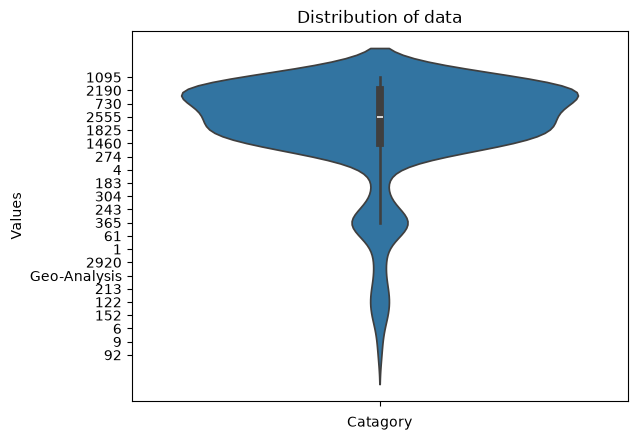

In [41]:
#Violin plot
sns.violinplot(data=df.head(500),y="Last Updated in number of days")
plt.title("Distribution of data")
plt.xlabel("Catagory")
plt.ylabel("Values")
plt.show()
               

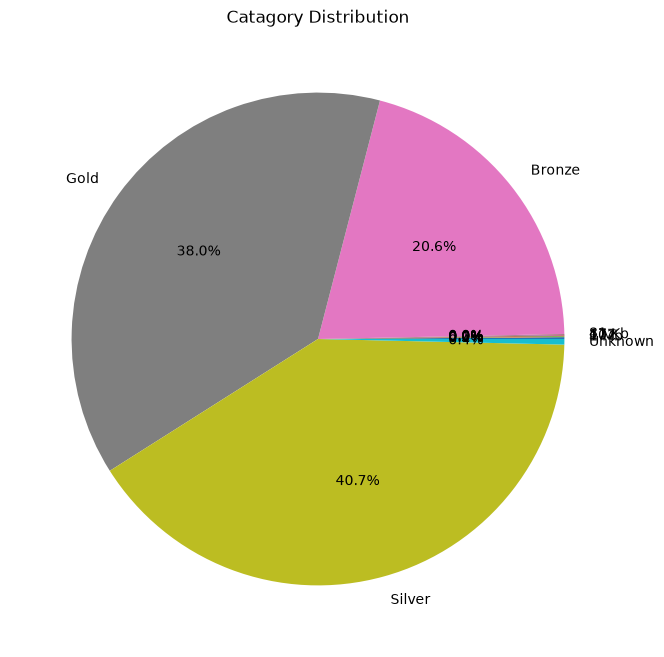

In [ ]:
#pie chart
data=df.groupby("Category").size()
data.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8,8)
)
plt.title("Catagory Distribution")
plt.show()


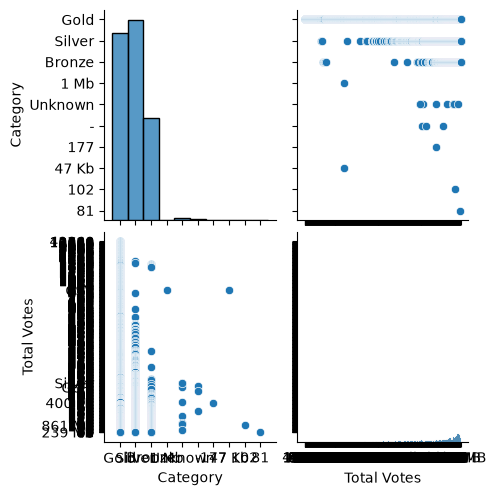

In [29]:
#Pairplot
df=pd.read_csv("KaggleDataset.csv")
#print(df.columns)
#print(df.head())
sns.pairplot(df,vars=['Category','Total Votes'])
#Total Votes
plt.show()

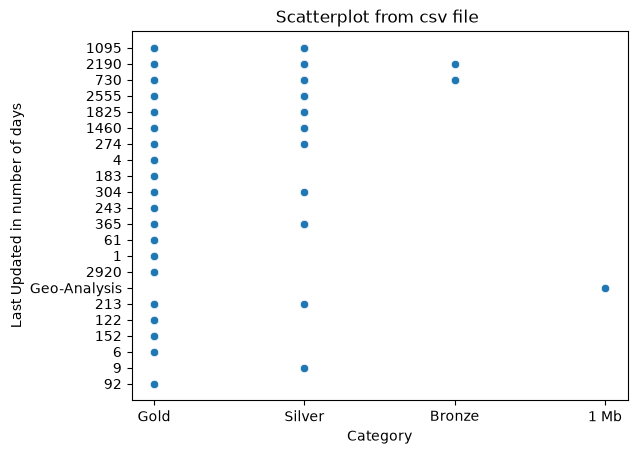

In [34]:
#Scatterplot 
sns.scatterplot(data=df.head(500),x="Category",y="Last Updated in number of days")
plt.title("Scatterplot from csv file ")
plt.show()